<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A03_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import seaborn as sns
import math

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("prokshitha/home-value-insights")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'home-value-insights' dataset.
Path to dataset files: /kaggle/input/home-value-insights


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
df = pd.read_csv("house_price_regression_dataset.csv")

df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [7]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
995,False
996,False
997,False
998,False


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [8]:
df.isnull().sum()

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [9]:
stats = df.describe()

display(stats)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [10]:
print("Частоти значень Neighborhood_Quality:")
print(df["Neighborhood_Quality"].value_counts().sort_index())

Частоти значень Neighborhood_Quality:
Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

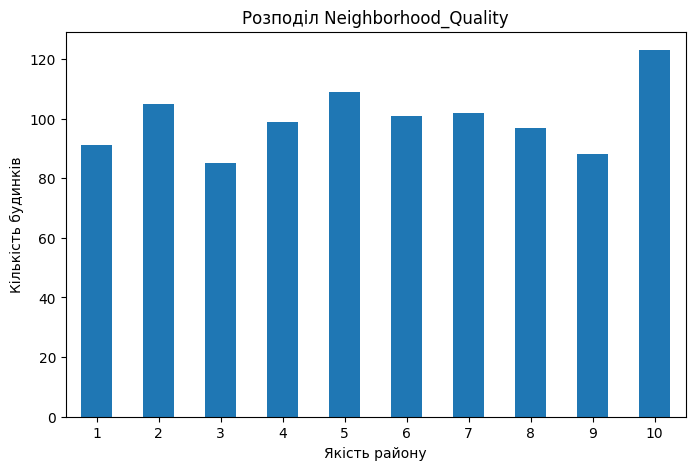

In [12]:
df["Neighborhood_Quality"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Якість району")
plt.ylabel("Кількість будинків")
plt.title("Розподіл Neighborhood_Quality")
plt.xticks(rotation=0)
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [13]:
print("Частоти значень Num_Bathrooms:")
print(df["Num_Bathrooms"].value_counts().sort_index())

Частоти значень Num_Bathrooms:
Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

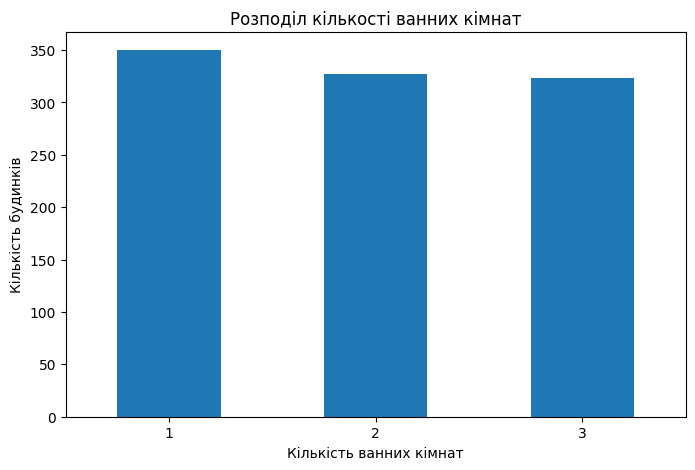

In [15]:
df["Num_Bathrooms"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість будинків")
plt.title("Розподіл кількості ванних кімнат")
plt.xticks(rotation=0)
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

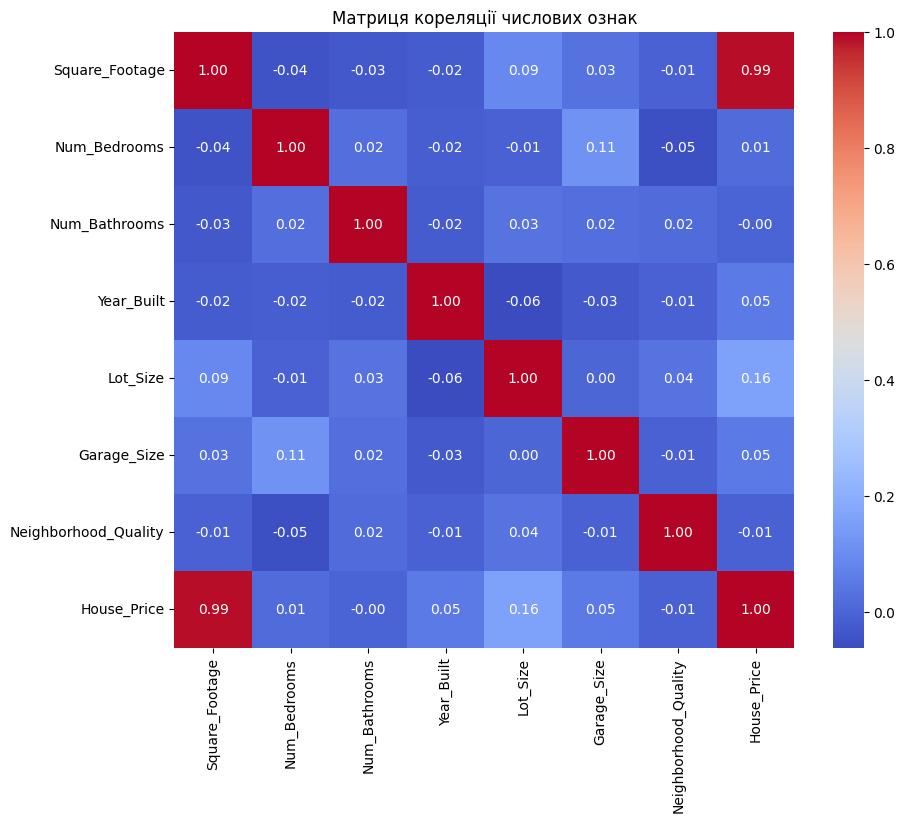

In [33]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Матриця кореляції числових ознак")
plt.show()

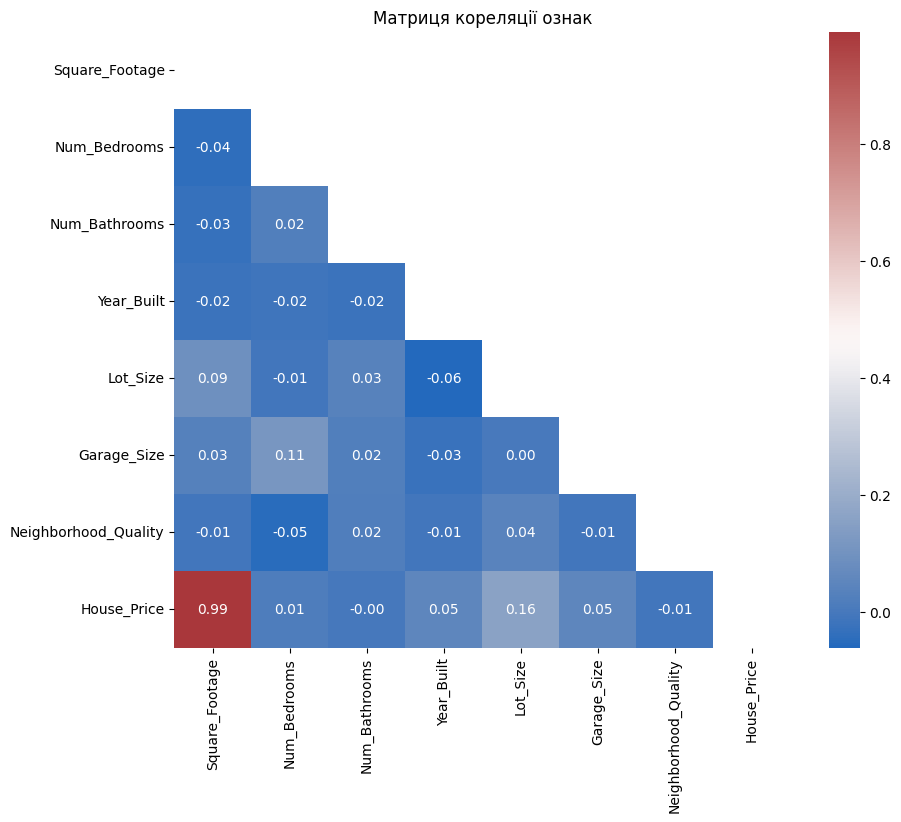

In [36]:
corr_matrix = df.corr(numeric_only=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    square=True
)

plt.title("Матриця кореляції ознак")
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [18]:
correlation_with_price = (
    df.corr(numeric_only=True)["House_Price"]
    .sort_values(ascending=False)
)

print("Кореляція ознак з House_Price:")
print(correlation_with_price)

Кореляція ознак з House_Price:
House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [20]:
X = df.drop("House_Price", axis=1)
y = df["House_Price"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Розмір X: (1000, 7)
Розмір y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (800, 7)
Тестова вибірка: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [22]:
linear_model = Pipeline([
    ("scale", StandardScaler()),
    ("reg", LinearRegression())
])

In [23]:
ridge_model = Pipeline([
    ("scale", StandardScaler()),
    ("reg", Ridge(alpha=1.0))
])

In [37]:
lasso_model = Pipeline([
    ("scale", StandardScaler()),
    ("reg", Lasso(alpha=0.1, max_iter=10000))
])

In [27]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [28]:
gradient_boosting_model = GradientBoostingRegressor(
    random_state=42
)

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [46]:
results = []

for name, model in models.items():
    # Навчання моделі
    model.fit(X_train, y_train)

    # Прогноз
    y_pred = model.predict(X_test)

    # Оцінювання
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,R2,MAE,MSE
0,Linear Regression,0.998426,8174.583600,1.014348e+08
1,Ridge,0.998410,8241.586911,1.024810e+08
2,Lasso,0.998426,8174.748374,1.014366e+08
3,Random Forest,0.993886,16114.289644,3.941317e+08
4,Gradient Boosting,0.996510,12305.217615,2.249656e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

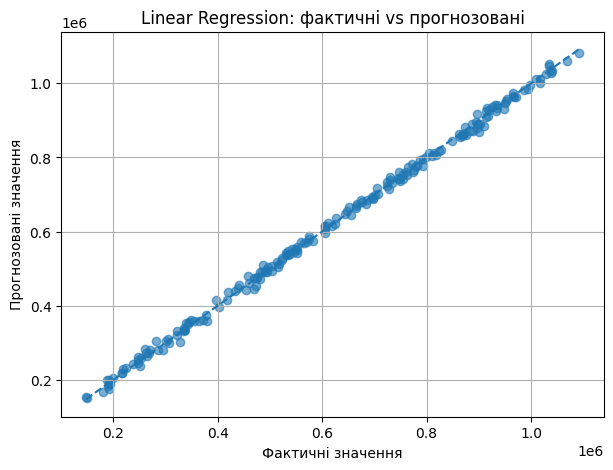

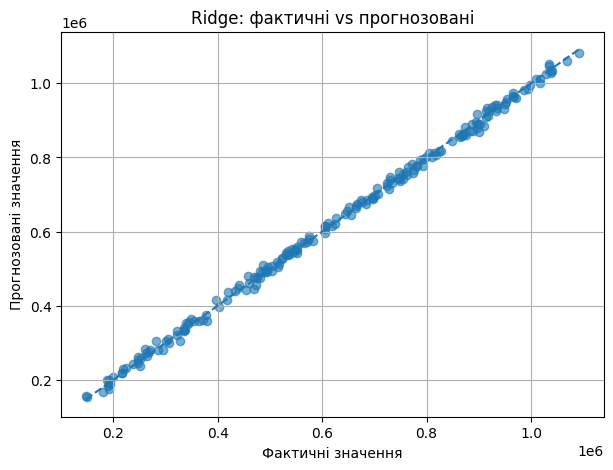

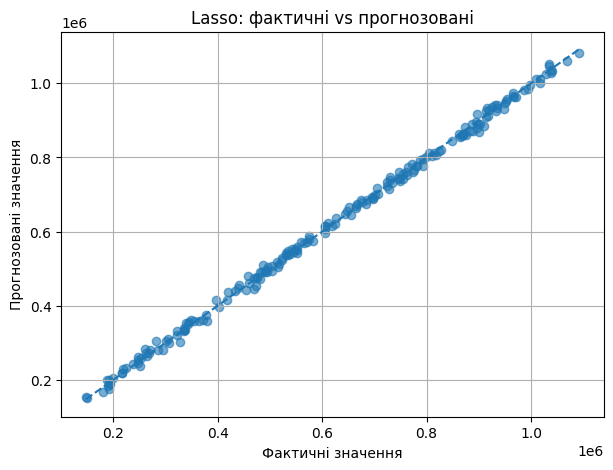

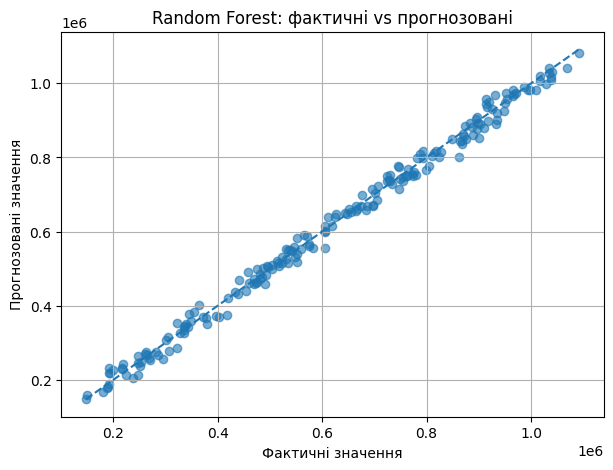

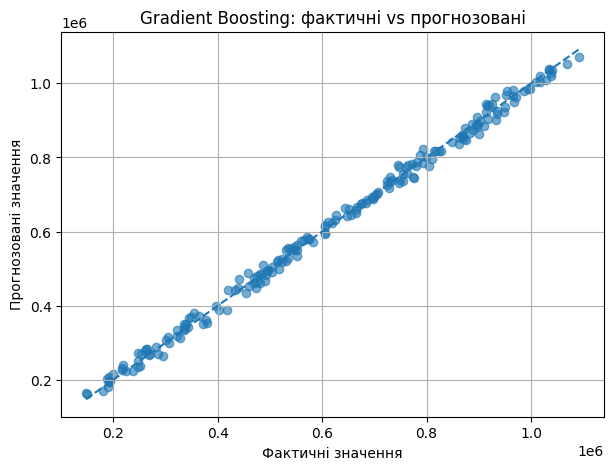

In [44]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred, alpha=0.6)

    # Лінія ідеального прогнозу
    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Фактичні значення")
    plt.ylabel("Прогнозовані значення")
    plt.title(f"{name}: фактичні vs прогнозовані")
    plt.grid(True)

    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [47]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_features": ["sqrt", "log2"],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Найкращі параметри:")
print(rf_grid.best_params_)

print("Найкращий R² на крос-валідації:")
print(rf_grid.best_score_)

Найкращі параметри:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Найкращий R² на крос-валідації:
0.9626779849469085


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [48]:
optimized_rf = RandomForestRegressor(
    **rf_grid.best_params_,
    random_state=42
)

optimized_rf.fit(X_train, y_train)

optimized_pred = optimized_rf.predict(X_test)

optimized_r2 = r2_score(y_test, optimized_pred)
optimized_mae = mean_absolute_error(y_test, optimized_pred)
optimized_mse = mean_squared_error(y_test, optimized_pred)

print("Оптимізована Random Forest:")
print(f"R²  = {optimized_r2:.4f}")
print(f"MAE = {optimized_mae:.4f}")
print(f"MSE = {optimized_mse:.4f}")

Оптимізована Random Forest:
R²  = 0.9666
MAE = 34521.3981
MSE = 2154491920.1376


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [49]:
basic_pred = random_forest_model.predict(X_test)

basic_r2 = r2_score(y_test, basic_pred)
basic_mae = mean_absolute_error(y_test, basic_pred)
basic_mse = mean_squared_error(y_test, basic_pred)

In [50]:
comparison_rf = pd.DataFrame({
    "Модель": [
        "Random Forest (базова)",
        "Random Forest (оптимізована)"
    ],
    "R²": [
        basic_r2,
        optimized_r2
    ],
    "MAE": [
        basic_mae,
        optimized_mae
    ],
    "MSE": [
        basic_mse,
        optimized_mse
    ]
})

display(comparison_rf)

,Модель,R²,MAE,MSE
0,Random Forest (базова),0.993886,16114.289644,3.941317e+08
1,Random Forest (оптимізована),0.966576,34521.398074,2.154492e+09


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**
Було виконано оптимізацію моделі Random Forest за допомогою GridSearchCV з використанням 5-кратної крос-валідації та метрики R². Було підібрано оптимальні значення параметрів n_estimators, max_features, max_depth та min_samples_split. Після оптимізації було повторно обчислено R², MAE та MSE на тестовій вибірці. Якщо оптимізована модель має більший R² та менші MAE і MSE порівняно з базовою, то якість прогнозування покращилася. У такому випадку використання оптимізованої Random Forest є доцільним. Якщо показники майже не змінилися або стали гіршими, значного ефекту від оптимізації немає.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [51]:
linear_pred = linear_model.predict(X_test)

# Створення таблиці
prediction_table = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": linear_pred,
    "Похибка, %": (
        np.abs(y_test.values - linear_pred) / y_test.values * 100
    )
})

# 10 випадкових рядків
display(
    prediction_table.sample(10, random_state=42).round(2)
)

,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**
У ході лабораторної роботи було побудовано та досліджено моделі Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting для прогнозування вартості нерухомості. Якість моделей оцінювалася за метриками R², MAE та MSE, що дозволило визначити найбільш ефективну модель. Для Random Forest було виконано підбір гіперпараметрів за допомогою GridSearchCV, що дозволило оптимізувати її параметри та порівняти результати з базовою моделлю. Прогнози на тестовій вибірці показали, наскільки точно моделі можуть передбачати ціну будинків. На якість прогнозування найбільше можуть впливати площа будинку, кількість спалень і ванних кімнат, рік побудови, розмір ділянки, гаража та якість району. Отже, застосування методів машинного навчання дає змогу ефективно прогнозувати вартість нерухомості та оцінювати вплив різних характеристик будинку на її